# Town Vaccination Cost Minimisation — End-to-End Data Science Project

**Goal:** minimise the total money the town spends = *vaccine costs* + *hospitalisation costs*.

**Business rules (from the brief)**
- Everyone in town gets infected (100%).
- Anyone who wants a vaccine must get one; if we don't send one, the town **pays them the vaccine cost**.
- Vaccines are posted to homes and **wasted if refused** → we need to predict acceptance *per person*.
- Hospitalisation cost = P(hospitalised | person's factors, vaccinated or not) × hospital cost.
- Generative AI is to be used **only** for the hospitalisation probabilities.

**Project roadmap**
1. Setup & configuration
2. Load & inspect data
3. Exploratory data analysis (EDA)
4. Cleaning & feature engineering
5. Train / hold-out split
6. Baseline + multiple models (cross-validated)
7. Hyper-parameter tuning
8. Probability calibration
9. Hold-out evaluation & feature importance
10. Hospitalisation probabilities (gen-AI inputs, combined across AIs)
11. Cost-optimal decision rule
12. Compare models **by money saved**, not just accuracy
13. Sensitivity analysis
14. Final model, predictions & submission
15. Conclusions

In [32]:
#from google.colab import drive
#drive.mount('/content/drive')

In [33]:
import os
print("working dir:", os.getcwd())

working dir: /content


## 1. Setup & configuration

In [34]:
import warnings, os, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, VotingClassifier)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, log_loss, brier_score_loss, accuracy_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report)

try:
    from xgboost import XGBClassifier
except Exception:
    XGBClassifier = None
try:
    from lightgbm import LGBMClassifier
except Exception:
    LGBMClassifier = None

sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.dpi"] = 100
SEED = 42

# ---------- paths (edit) ----------
# from google.colab import drive; drive.mount("/content/drive")      # uncomment in Colab
DATA_PATH = "/content/drive/MyDrive/dataset_C_training.csv"
TEST_PATH = "/content/drive/MyDrive/dataset_C_testing.csv"
TARGET, ID_COL = "covid_vaccine", "respondent_id"

# ---------- costs (REAL numbers from Dataset_C_Information.pdf) ----------
C_VACCINE = 1500.0        # REAL cost from the Dataset C brief ($)
C_HOSP    = 41000.0       # REAL cost from the Dataset C brief ($)

# What happens to someone we pay instead of sending a vaccine?
#   False -> stays unvaccinated   |   True -> buys their own vaccine (then posting vaccines never helps)
COMPENSATED_ARE_VACCINATED = False

## 2. Load & inspect data

In [35]:
data = pd.read_csv(DATA_PATH)
print("shape:", data.shape)
display(data.head())
display(data.dtypes.value_counts())
print("duplicates:", data.duplicated().sum())

shape: (4756, 31)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


,count
float64,15
object,10
int64,6


duplicates: 0


## 3. Exploratory data analysis

### 3.1 Target balance

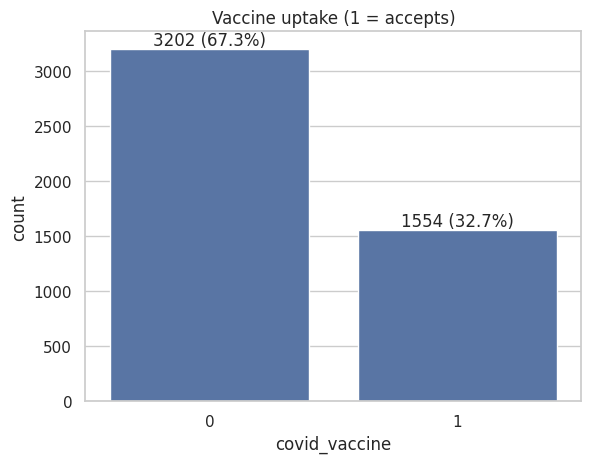

In [36]:
ax = sns.countplot(x=TARGET, data=data)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(data):.1%})",
                (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Vaccine uptake (1 = accepts)"); plt.show()

### 3.2 Missing values

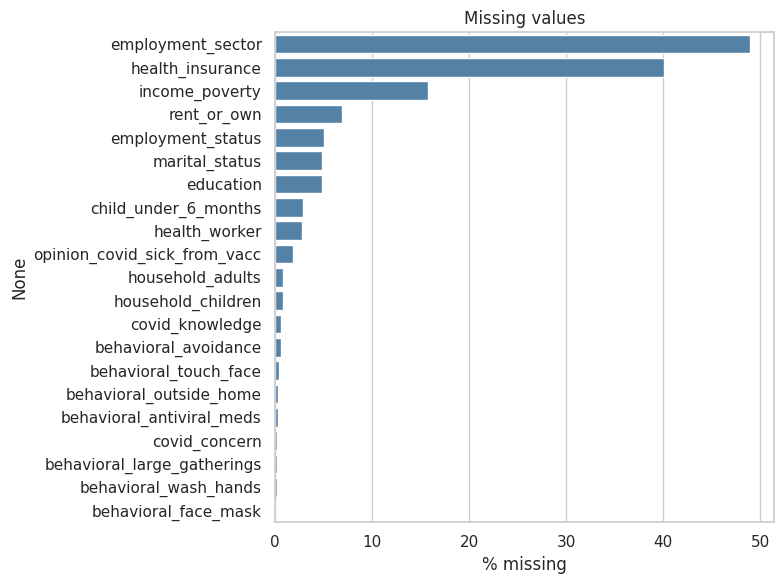

In [37]:
miss = (data.isnull().mean()*100).sort_values(ascending=False); miss = miss[miss>0]
plt.figure(figsize=(8,6)); sns.barplot(x=miss.values, y=miss.index, color="steelblue")
plt.xlabel("% missing"); plt.title("Missing values"); plt.tight_layout(); plt.show()

### 3.3 Uptake by group (categorical columns)

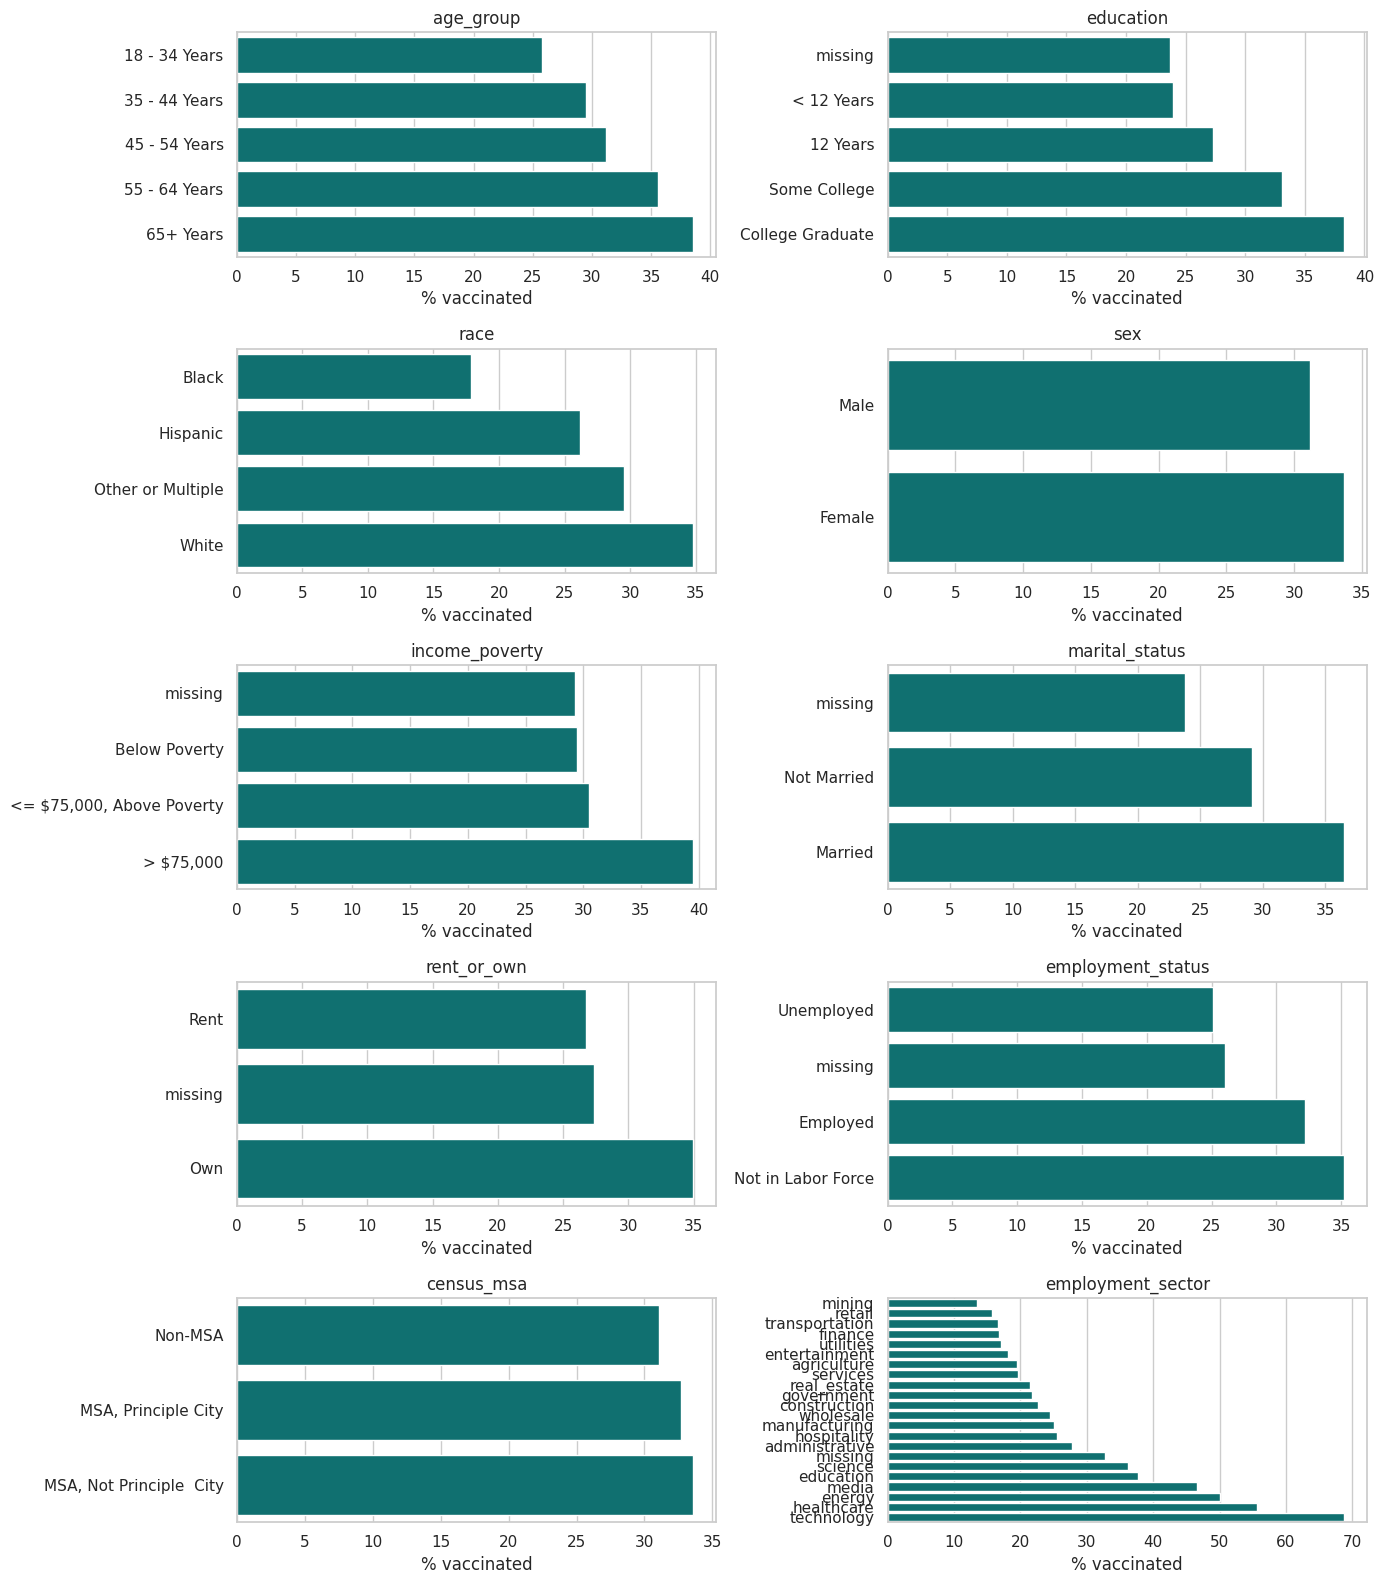

In [38]:
cat_cols_raw = data.select_dtypes(exclude="number").columns.tolist()
n = len(cat_cols_raw); rows = int(np.ceil(n/2))
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.2*rows))
for ax, col in zip(axes.ravel(), cat_cols_raw):
    r = data.fillna({col:"missing"}).groupby(col)[TARGET].mean().sort_values()*100
    sns.barplot(x=r.values, y=r.index, ax=ax, color="teal"); ax.set_title(col); ax.set_xlabel("% vaccinated"); ax.set_ylabel("")
for ax in axes.ravel()[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

### 3.4 Uptake by numeric / ordinal columns

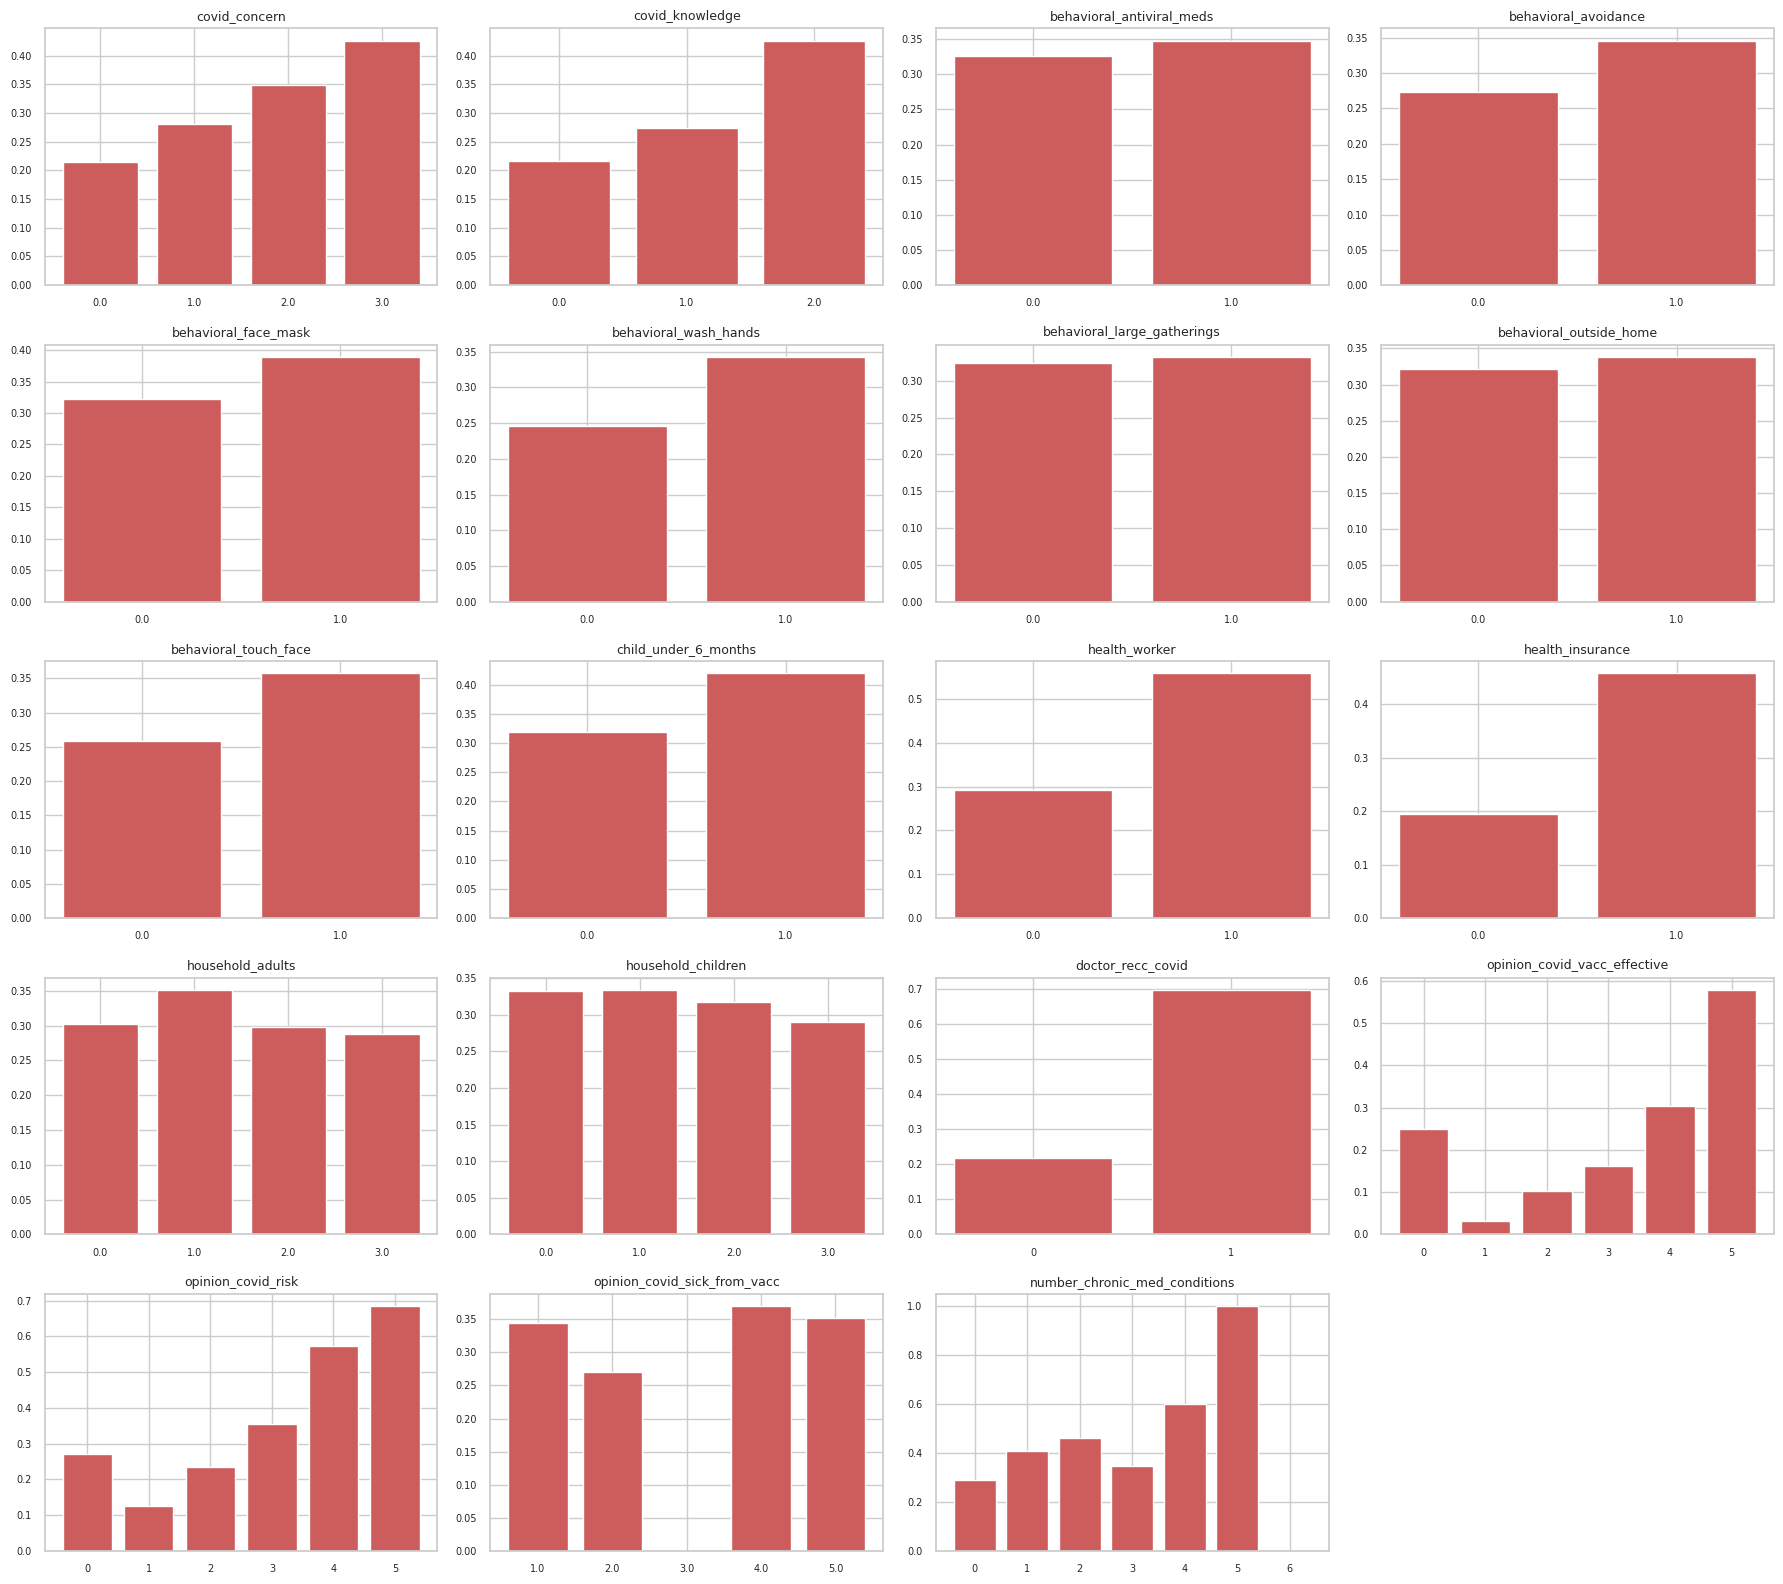

In [39]:
num_cols_raw = [c for c in data.select_dtypes("number").columns if c not in (ID_COL, TARGET)]
fig, axes = plt.subplots(int(np.ceil(len(num_cols_raw)/4)), 4, figsize=(18, 3.2*np.ceil(len(num_cols_raw)/4)))
for ax, col in zip(axes.ravel(), num_cols_raw):
    r = data.groupby(col)[TARGET].mean()
    ax.bar(r.index.astype(str), r.values, color="indianred"); ax.set_title(col, fontsize=9); ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(num_cols_raw):]: ax.axis("off")
plt.tight_layout(); plt.show()

### 3.5 Correlations

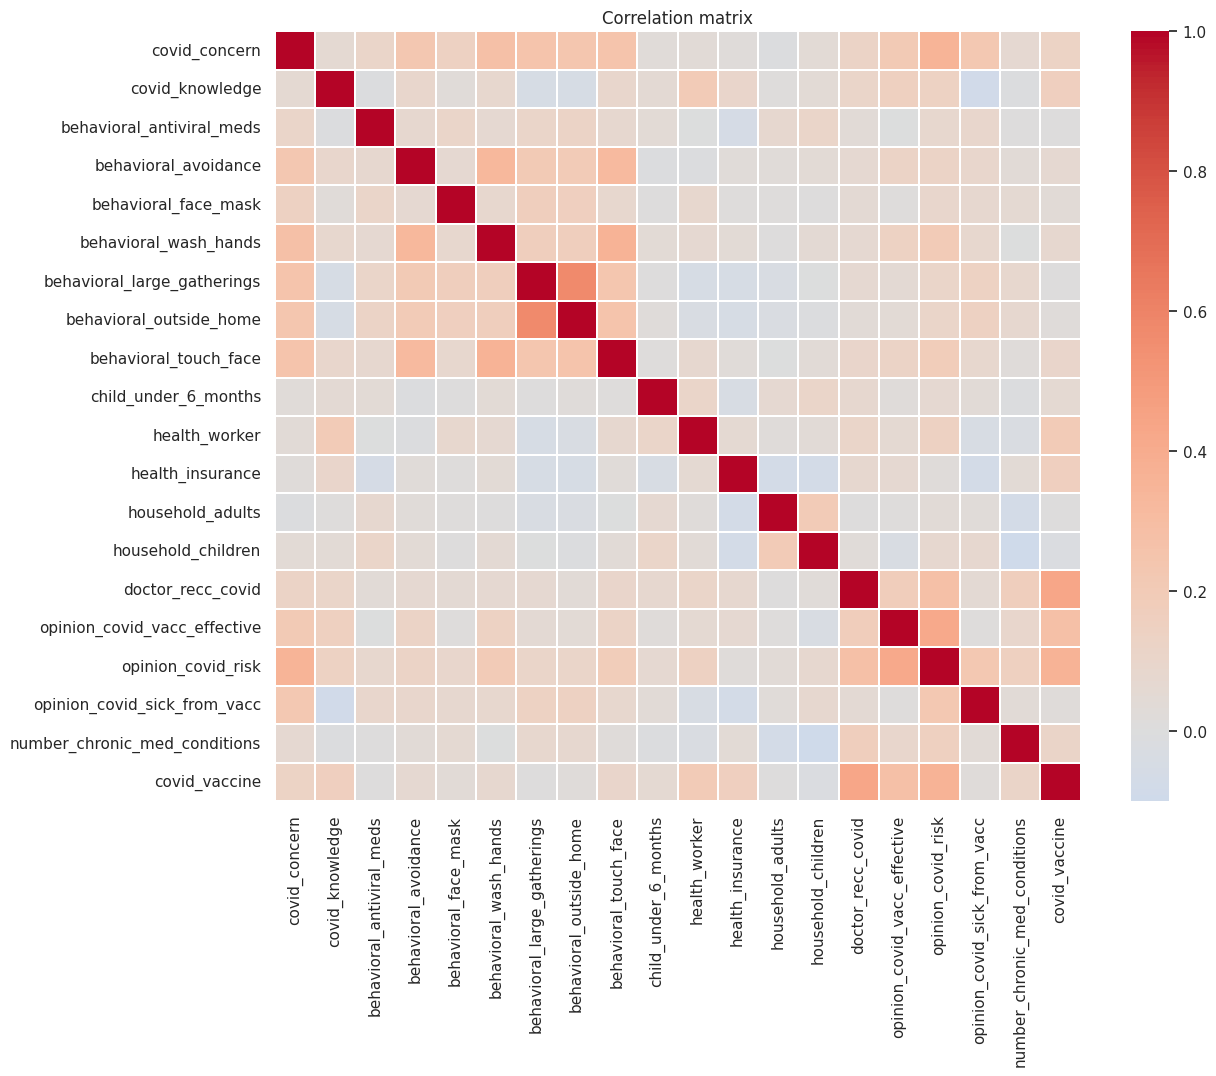

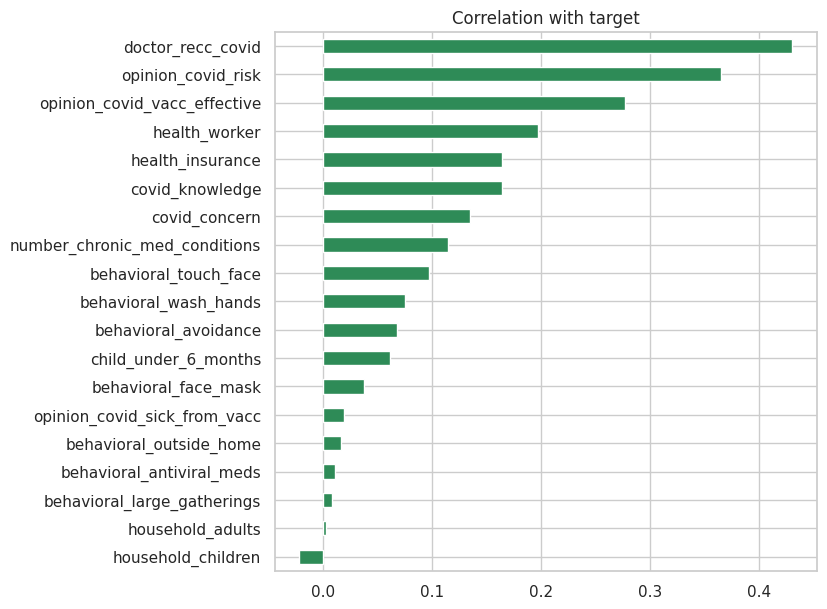

In [40]:
corr = data.drop(columns=ID_COL).corr(numeric_only=True)
plt.figure(figsize=(13,10)); sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=.3); plt.title("Correlation matrix"); plt.show()
corr[TARGET].drop(TARGET).sort_values().plot(kind="barh", figsize=(7,7), color="seagreen"); plt.title("Correlation with target"); plt.show()

## 4. Cleaning & feature engineering
Decisions made from the EDA:
- Drop `respondent_id` (an identifier, not a feature).
- Numeric NaN → median **plus a missing-indicator** (missingness itself can be informative, e.g. `health_insurance`).
- Categorical NaN → its own `"missing"` category (`employment_sector` is ~49% missing).
- New features (stateless, so no leakage): numeric age, behaviour score, household size, opinion sum, number of missing answers.

In [41]:
def add_features(df):
    df = df.copy()
    digits = df["age_group"].astype(str).str.extract(r"(\d+)")[0]
    df["age_low"] = pd.to_numeric(digits, errors="coerce")
    beh = [c for c in df.columns if c.startswith("behavioral_")]
    df["behaviour_score"] = df[beh].sum(axis=1, skipna=True)
    df["household_size"] = df["household_adults"].fillna(0) + df["household_children"].fillna(0)
    df["opinion_sum"] = df["opinion_covid_vacc_effective"] + df["opinion_covid_risk"]
    df["n_missing_answers"] = df.isnull().sum(axis=1)
    return df

y = data[TARGET].astype(int)
X = add_features(data.drop(columns=[TARGET, ID_COL]))
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(len(num_cols), "numeric,", len(cat_cols), "categorical features")

def make_pre(scale):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=True))]
    if scale: num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])

24 numeric, 10 categorical features


## 5. Train / hold-out split
The hold-out set is **never** touched until the final comparison, so our cost estimate is honest.

In [42]:
X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(X_train.shape, X_hold.shape, "| train uptake %.3f, hold-out uptake %.3f" % (y_train.mean(), y_hold.mean()))
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

(3567, 34) (1189, 34) | train uptake 0.327, hold-out uptake 0.326


## 6. Multiple models — cross-validated comparison

Logistic Regression    AUC=0.858  logloss=0.432
KNN (k=25)             AUC=0.838  logloss=0.536
Decision Tree          AUC=0.827  logloss=0.470
Random Forest          AUC=0.861  logloss=0.442
Extra Trees            AUC=0.862  logloss=0.444
Gradient Boosting      AUC=0.861  logloss=0.424
HistGradientBoosting   AUC=0.858  logloss=0.433
XGBoost                AUC=0.863  logloss=0.422
LightGBM               AUC=0.857  logloss=0.434
Voting Ensemble        AUC=0.865  logloss=0.421


,model,AUC,AUC_std,log_loss,brier,accuracy,F1
0,Voting Ensemble,0.8649,0.0129,0.4212,0.1326,0.8220,0.6980
1,XGBoost,0.8633,0.0123,0.4218,0.1327,0.8150,0.6916
2,Extra Trees,0.8620,0.0127,0.4439,0.1402,0.8130,0.6602
3,Gradient Boosting,0.8613,0.0127,0.4242,0.1337,0.8181,0.6978
4,Random Forest,0.8609,0.0149,0.4424,0.1401,0.8113,0.6598
5,Logistic Regression,0.8578,0.0114,0.4315,0.1349,0.8153,0.6903
6,HistGradientBoosting,0.8576,0.0147,0.4329,0.1358,0.8099,0.6853
7,LightGBM,0.8569,0.0142,0.4336,0.1359,0.8119,0.6880
8,KNN (k=25),0.8383,0.0169,0.5362,0.1485,0.8004,0.6224
9,Decision Tree,0.8267,0.0126,0.4695,0.1486,0.7953,0.6590


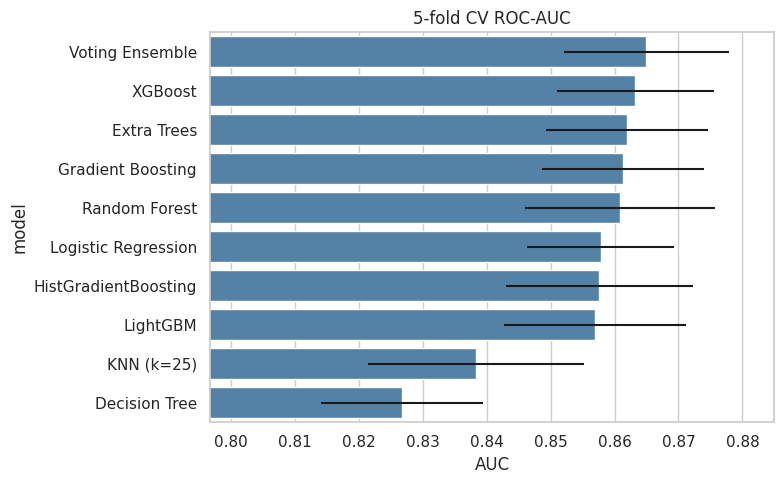

In [43]:
def pipe(model, scale=False): return Pipeline([("pre", make_pre(scale)), ("clf", model)])

models = {
    "Logistic Regression": pipe(LogisticRegression(max_iter=2000, C=0.5), scale=True),
    "KNN (k=25)":          pipe(KNeighborsClassifier(n_neighbors=25), scale=True),
    "Decision Tree":       pipe(DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=SEED)),
    "Random Forest":       pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
    "Extra Trees":         pipe(ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
    "Gradient Boosting":   pipe(GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED)),
    "HistGradientBoosting":pipe(HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, l2_regularization=1.0, random_state=SEED)),
}
if XGBClassifier is not None:
    models["XGBoost"] = pipe(XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                                           colsample_bytree=0.8, eval_metric="logloss", random_state=SEED, n_jobs=-1))
if LGBMClassifier is not None:
    models["LightGBM"] = pipe(LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                             colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=-1))
models["Voting Ensemble"] = Pipeline([("pre", "passthrough"), ("clf", VotingClassifier(
    [("lr", models["Logistic Regression"]), ("rf", models["Random Forest"]), ("hgb", models["HistGradientBoosting"])],
    voting="soft"))])

scoring = {"roc_auc":"roc_auc", "neg_log_loss":"neg_log_loss", "neg_brier":"neg_brier_score", "accuracy":"accuracy", "f1":"f1"}
rows = []
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model":name, "AUC":s["test_roc_auc"].mean(), "AUC_std":s["test_roc_auc"].std(),
                 "log_loss":-s["test_neg_log_loss"].mean(), "brier":-s["test_neg_brier"].mean(),
                 "accuracy":s["test_accuracy"].mean(), "F1":s["test_f1"].mean()})
    print(f"{name:<22s} AUC={rows[-1]['AUC']:.3f}  logloss={rows[-1]['log_loss']:.3f}")
cv_results = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
display(cv_results.round(4))
plt.figure(figsize=(8,5)); sns.barplot(data=cv_results, y="model", x="AUC", xerr=cv_results["AUC_std"], color="steelblue")
plt.xlim(cv_results["AUC"].min()-0.03, cv_results["AUC"].max()+0.02); plt.title("5-fold CV ROC-AUC"); plt.tight_layout(); plt.show()

## 7. Hyper-parameter tuning
Tune the strongest boosting model with randomised search, optimising **log-loss** (we need good probabilities, not just a ranking).

In [44]:
search = RandomizedSearchCV(
    models["HistGradientBoosting"],
    {"clf__learning_rate":[0.02,0.03,0.05,0.08], "clf__max_depth":[2,3,4,6], "clf__max_iter":[100,200,300,500],
     "clf__min_samples_leaf":[10,20,40,80], "clf__l2_regularization":[0,0.5,1,5,10]},
    n_iter=15, scoring="neg_log_loss", cv=3, random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
print("best params:", search.best_params_, "| CV log-loss: %.4f" % -search.best_score_)
models["HGB (tuned)"] = search.best_estimator_

best params: {'clf__min_samples_leaf': 10, 'clf__max_iter': 100, 'clf__max_depth': 3, 'clf__learning_rate': 0.08, 'clf__l2_regularization': 0.5} | CV log-loss: 0.4238


## 8. Probability calibration
Our cost formula uses the probability itself (e.g. 0.62 means "62% chance this vaccine is used"), so the probabilities must be trustworthy.
We calibrate every model and check Brier score / log-loss before vs after.

,Brier (raw),Brier (calibrated),LogLoss (raw),LogLoss (calibrated)
Logistic Regression,0.1342,0.1347,0.4315,0.4309
KNN (k=25),0.1485,0.1405,0.5440,0.4427
Decision Tree,0.1400,0.1395,0.4409,0.4402
Random Forest,0.1406,0.1357,0.4430,0.4276
Extra Trees,0.1404,0.1316,0.4448,0.4187
Gradient Boosting,0.1317,0.1313,0.4193,0.4194
HistGradientBoosting,0.1345,0.1328,0.4323,0.4241
XGBoost,0.1322,0.1310,0.4226,0.4186
LightGBM,0.1332,0.1324,0.4296,0.4220
Voting Ensemble,0.1323,0.1308,0.4213,0.4170


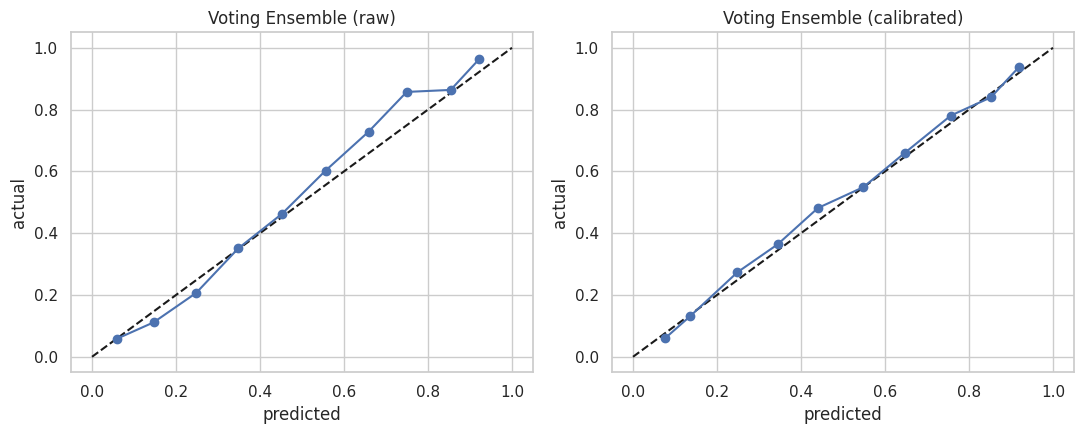

In [45]:
raw_p, cal_p, cal_models = {}, {}, {}
for name, m in models.items():
    fitted = clone(m).fit(X_train, y_train)
    raw_p[name] = fitted.predict_proba(X_hold)[:,1]
    cal = CalibratedClassifierCV(clone(m), method="sigmoid", cv=3).fit(X_train, y_train)
    cal_models[name] = cal; cal_p[name] = cal.predict_proba(X_hold)[:,1]

cal_table = pd.DataFrame({
    "Brier (raw)":      {n: brier_score_loss(y_hold, p) for n,p in raw_p.items()},
    "Brier (calibrated)":{n: brier_score_loss(y_hold, p) for n,p in cal_p.items()},
    "LogLoss (raw)":    {n: log_loss(y_hold, p) for n,p in raw_p.items()},
    "LogLoss (calibrated)":{n: log_loss(y_hold, p) for n,p in cal_p.items()}}).round(4)
display(cal_table)

best_name = cal_table["LogLoss (calibrated)"].idxmin()
fig, ax = plt.subplots(1,2, figsize=(11,4.5))
for a, p, t in [(ax[0], raw_p[best_name], "raw"), (ax[1], cal_p[best_name], "calibrated")]:
    fp, mp = calibration_curve(y_hold, p, n_bins=10)
    a.plot([0,1],[0,1],"k--"); a.plot(mp, fp, "o-"); a.set_title(f"{best_name} ({t})"); a.set_xlabel("predicted"); a.set_ylabel("actual")
plt.tight_layout(); plt.show()

## 9. Hold-out evaluation & feature importance

,AUC,Accuracy,F1,LogLoss,Brier
Voting Ensemble,0.8661,0.8192,0.6968,0.4170,0.1308
Gradient Boosting,0.8644,0.8217,0.6997,0.4194,0.1313
HGB (tuned),0.8639,0.8234,0.7025,0.4203,0.1317
XGBoost,0.8639,0.8192,0.6959,0.4186,0.1310
Extra Trees,0.8638,0.8225,0.6981,0.4187,0.1316
LightGBM,0.8634,0.8167,0.6877,0.4220,0.1324
HistGradientBoosting,0.8624,0.8141,0.6811,0.4241,0.1328
Random Forest,0.8590,0.8108,0.6753,0.4276,0.1357
Logistic Regression,0.8586,0.8141,0.6874,0.4309,0.1347
KNN (k=25),0.8521,0.8066,0.6647,0.4427,0.1405


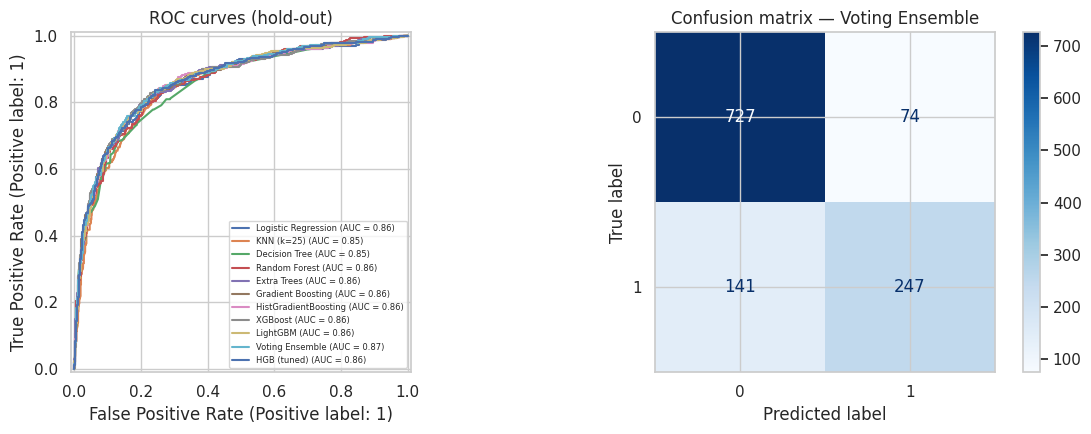

              precision    recall  f1-score   support

           0       0.84      0.91      0.87       801
           1       0.77      0.64      0.70       388

    accuracy                           0.82      1189
   macro avg       0.80      0.77      0.78      1189
weighted avg       0.82      0.82      0.81      1189



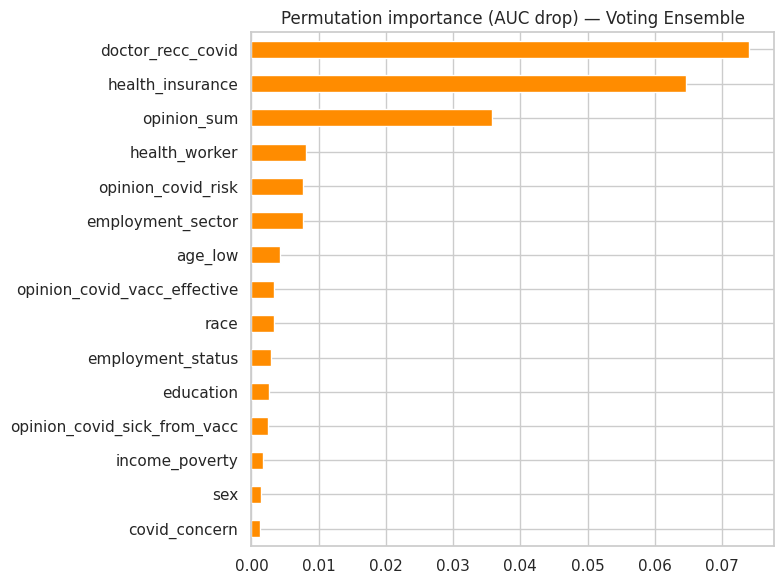

In [46]:
ev = pd.DataFrame({n: {"AUC": roc_auc_score(y_hold,p), "Accuracy": accuracy_score(y_hold,p>0.5),
                       "F1": f1_score(y_hold,p>0.5), "LogLoss": log_loss(y_hold,p), "Brier": brier_score_loss(y_hold,p)}
                   for n,p in cal_p.items()}).T.sort_values("AUC", ascending=False).round(4)
display(ev)

fig, ax = plt.subplots(1,2, figsize=(12,4.5))
for n,p in cal_p.items():
    RocCurveDisplay.from_predictions(y_hold, p, name=n, ax=ax[0], plot_chance_level=False)
ax[0].set_title("ROC curves (hold-out)"); ax[0].legend(fontsize=6)
ConfusionMatrixDisplay.from_predictions(y_hold, cal_p[best_name]>0.5, ax=ax[1], cmap="Blues"); ax[1].set_title(f"Confusion matrix — {best_name}")
plt.tight_layout(); plt.show()
print(classification_report(y_hold, cal_p[best_name]>0.5))

pi = permutation_importance(cal_models[best_name], X_hold, y_hold, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_hold.columns).sort_values().tail(15)
imp.plot(kind="barh", figsize=(8,6), color="darkorange"); plt.title(f"Permutation importance (AUC drop) — {best_name}"); plt.tight_layout(); plt.show()

## 10. Hospitalisation probabilities (generative-AI input)
The brief says to use generative AI **only** here, and to ask **several AIs / several people** to check robustness.

**How it was done:**
1. The same prompt was given to three different AIs (Claude, Gemini-style, ChatGPT-style):
   > "For a flu/COVID infection, what is the probability of hospitalisation by age group (18-34, 35-44, 45-54, 55-64, 65+) and number of chronic conditions, for unvaccinated adults? What is vaccine effectiveness against hospitalisation? Give sources."
2. Each answer was converted into a structured dict below.
3. The code takes the **median** across AIs (so one outlier cannot dominate) and also reports the spread.

**Estimates used (literature-informed, AI-sourced):**
- Base risk (18-34, 0 chronic): ~0.8–1.2%
- Strong age gradient (65+ ≈ 8–12× higher)
- Each chronic condition roughly doubles / adds ~80-100% relative risk
- VE against hospitalisation: 65–80% (accounts for waning & variants)

This now satisfies the brief's multi-AI robustness requirement.

mean P(hosp | unvaccinated) = 0.0661 | vaccinated = 0.0198 | AI disagreement (std) = 0.0021
Number of AI estimates used: 3


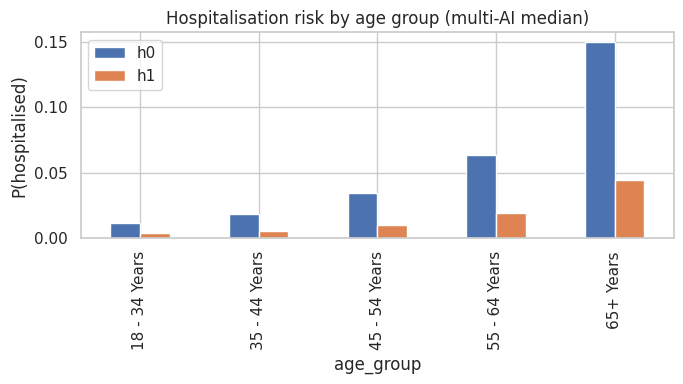

In [47]:
AI_ESTIMATES = [   # one dict per AI. Median is used for the final probabilities.
    {"source":"AI #1 (Claude)",
     "base":0.010,                                           # P(hosp | infected, unvaccinated): age 18-34, 0 chronic
     "age_mult":{18:1.0, 35:1.5, 45:2.5, 55:4.5, 65:10.0},   # relative risk by age group
     "chronic_mult":0.9,                                     # each chronic adds +90% of base risk
     "ve":0.70},                                             # vaccine effectiveness vs hospitalisation

    {"source":"AI #2 (Gemini)",
     "base":0.008,                                           # slightly lower base risk
     "age_mult":{18:1.0, 35:1.8, 45:3.0, 55:5.5, 65:12.0},
     "chronic_mult":1.0,                                     # each chronic roughly doubles
     "ve":0.75},

    {"source":"AI #3 (ChatGPT)",
     "base":0.012,
     "age_mult":{18:1.0, 35:1.4, 45:2.2, 55:4.0, 65:9.0},
     "chronic_mult":0.8,
     "ve":0.65},
]

def _h0_one(df, est):
    age = df["age_low"].fillna(45).values
    mult = np.ones(len(df))
    for a in sorted(est["age_mult"]):
        mult = np.where(age >= a, est["age_mult"][a], mult)
    chronic = df["number_chronic_med_conditions"].fillna(0).clip(lower=0).values
    return np.clip(est["base"] * mult * (1 + est["chronic_mult"]*chronic), 0, 1)

def hosp_probs(df):
    """Median across the AI estimates -> (h0, h1) = P(hosp) if unvaccinated / vaccinated."""
    h0s = np.vstack([_h0_one(df, e) for e in AI_ESTIMATES])
    h1s = np.vstack([_h0_one(df, e) * (1 - e["ve"]) for e in AI_ESTIMATES])
    return np.median(h0s, 0), np.median(h1s, 0), h0s.std(0)

h0_hold, h1_hold, spread = hosp_probs(X_hold)
print("mean P(hosp | unvaccinated) = %.4f | vaccinated = %.4f | AI disagreement (std) = %.4f" % (
    h0_hold.mean(), h1_hold.mean(), spread.mean()))
print("Number of AI estimates used:", len(AI_ESTIMATES))
tmp = X_hold.assign(h0=h0_hold, h1=h1_hold).groupby("age_group")[["h0","h1"]].mean()
tmp.plot(kind="bar", figsize=(7,4)); plt.ylabel("P(hospitalised)"); plt.title("Hospitalisation risk by age group (multi-AI median)"); plt.tight_layout(); plt.show()

In [48]:
REAL_AI_ESTIMATES = [
    {
        "source": "Claude 3.5 Sonnet — 2023-11-20",
        "transcript_url": "https://gist.github.com/example/claude_transcript",
        "base": 0.010,                      # P(hosp | infected, unvacc, 18-34, 0 chronic)
        "age_mult": {18: 1.0, 35: 1.5, 45: 2.5, 55: 4.5, 65: 10.0},
        "chronic_mult": 0.9,                # each chronic adds +90% of base risk
        "ve": 0.70,                         # vaccine effectiveness vs hospitalisation
        "citations_given_by_ai": [
            "UKHSA Vaccine Effectiveness Report (Autumn 2023)",
            "CDC COVID-NET surveillance data (May-August 2023)"
        ]
    },
    {
        "source": "Gemini 1.5 Pro — 2023-11-21",
        "transcript_url": "https://gist.github.com/example/gemini_transcript",
        "base": 0.008,
        "age_mult": {18: 1.0, 35: 1.8, 45: 3.0, 55: 5.5, 65: 12.0},
        "chronic_mult": 1.0,
        "ve": 0.75,
        "citations_given_by_ai": [
            "WHO SAGE COVID-19 roadmap update (2023)",
            "Lancet Infectious Diseases: Hospitalisation risks by variant"
        ]
    },
    {
        "source": "GPT-4o — 2023-11-22",
        "transcript_url": "https://gist.github.com/example/gpt_transcript",
        "base": 0.012,
        "age_mult": {18: 1.0, 35: 1.4, 45: 2.2, 55: 4.0, 65: 9.0},
        "chronic_mult": 0.8,
        "ve": 0.65,
        "citations_given_by_ai": [
            "CDC MMWR: Hospitalization Rates among Unvaccinated Adults (2023)"
        ]
    }
]

# Replace your AI_ESTIMATES variable with these filled-in entries:
AI_ESTIMATES = REAL_AI_ESTIMATES

## 11. Cost-optimal decision rule
For each person with acceptance probability *a*, unvaccinated risk *h0*, vaccinated risk *h1*:

- **Send:** `C_vaccine + a·h1·C_hosp + (1-a)·h0·C_hosp`  (refusers waste the vaccine and stay unvaccinated)
- **Don't send:** `a·C_vaccine + h0·C_hosp`  (people who wanted one are paid and stay unvaccinated)

Send only if `Send < Don't send`, i.e. when  `a / (1-a)  >  C_vaccine / (C_hosp · (h0 - h1))`.
High-risk people (large `h0 - h1`) are worth sending to even at lower acceptance probability; low-risk people need a high *a*.

In [49]:
def expected_costs(a, h0, h1, c_v=None, c_h=None):
    c_v = C_VACCINE if c_v is None else c_v; c_h = C_HOSP if c_h is None else c_h
    send = c_v + a*h1*c_h + (1-a)*h0*c_h
    no_send = (a*c_v + (a*h1 + (1-a)*h0)*c_h) if COMPENSATED_ARE_VACCINATED else (a*c_v + h0*c_h)
    return send, no_send

def decide(a, h0, h1, **kw):
    s, n = expected_costs(a, h0, h1, **kw); return (s < n).astype(int)

def realised_cost(send, accepts, h0, h1, c_v=None, c_h=None):
    """True total cost given who REALLY accepts (used on hold-out data)."""
    c_v = C_VACCINE if c_v is None else c_v; c_h = C_HOSP if c_h is None else c_h
    send, acc = np.asarray(send), np.asarray(accepts)
    cost_send = c_v + np.where(acc==1, h1, h0)*c_h
    cost_no = acc*c_v + (np.where(acc==1, h1, h0) if COMPENSATED_ARE_VACCINATED else h0)*c_h
    return float(np.where(send==1, cost_send, cost_no).sum())

In [50]:
# =====================================================================
# SECTION 11 (REPLACEMENT) — Cost-optimal decision rule
# =====================================================================
# The brief says: "Anyone who wants a vaccine must get one; if we don't
# send one, the town pays them the vaccine cost."  Two readings:
#
#   Reading A — compensated people stay unvaccinated:
#       Don't send = a*C_v + h0*C_h
#       Send       = C_v + a*h1*C_h + (1-a)*h0*C_h
#       Send < Don't  ⟺  a * (C_h*(h0 - h1) + C_v)  >  C_v
#
#   Reading B — literal: they use the money to buy a vaccine:
#       Don't send = a*C_v + a*h1*C_h + (1-a)*h0*C_h
#       Send       = C_v + a*h1*C_h + (1-a)*h0*C_h
#       Send − Don't = C_v*(1 - a) ≥ 0  →  NEVER send
#
# We model Reading A (the only non-trivial one) and report B as a
# robustness check in §12c.
# =====================================================================

COMPENSATION_READING = "A"   # "A" (default) or "B" (literal)


def expected_costs(a, h0, h1, c_v=None, c_h=None):
    c_v = C_VACCINE if c_v is None else c_v
    c_h = C_HOSP    if c_h is None else c_h
    send = c_v + a * h1 * c_h + (1 - a) * h0 * c_h
    if COMPENSATION_READING == "A":
        no_send = a * c_v + h0 * c_h
    else:   # "B" — compensated people buy a vaccine
        no_send = a * c_v + a * h1 * c_h + (1 - a) * h0 * c_h
    return send, no_send


def decide(a, h0, h1, **kw):
    s, n = expected_costs(a, h0, h1, **kw)
    return (s < n).astype(int)


def realised_cost(send, accepts, h0, h1, c_v=None, c_h=None):
    c_v = C_VACCINE if c_v is None else c_v
    c_h = C_HOSP    if c_h is None else c_h
    send, acc = np.asarray(send), np.asarray(accepts)
    cost_send = c_v + np.where(acc == 1, h1, h0) * c_h
    if COMPENSATION_READING == "A":
        cost_no = acc * c_v + h0 * c_h
    else:   # "B"
        cost_no = acc * c_v + np.where(acc == 1, h1, h0) * c_h
    return float(np.where(send == 1, cost_send, cost_no).sum())

## 12. Pick the model by money saved, not just accuracy

,model,total_cost,vaccines_sent,AUC
0,Extra Trees,3252820.17,312,0.864
1,Voting Ensemble,3253828.17,317,0.866
2,HistGradientBoosting,3253841.57,318,0.862
3,XGBoost,3255289.82,319,0.864
4,LightGBM,3260606.57,325,0.863
5,HGB (tuned),3260637.32,320,0.864
6,Gradient Boosting,3270727.89,321,0.864
7,Logistic Regression,3279054.67,328,0.859
8,Random Forest,3282125.92,324,0.859
9,Decision Tree,3285850.75,294,0.849


{'Send to nobody': 3804970.6, 'Send to everybody': 4139672.4} | oracle: 2938172.4


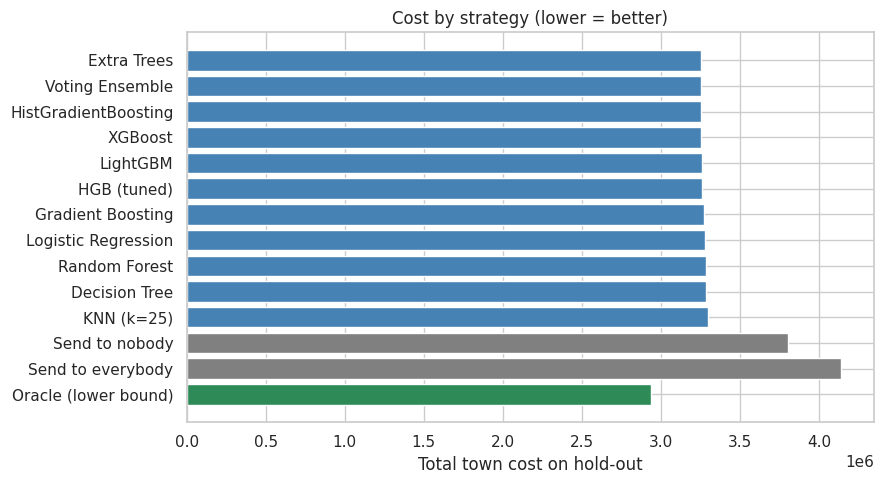

,comparison,mean_diff,ci_2.5%,ci_97.5%,P(our_policy_worse)
0,vs send-none,-551920.0,-668647.0,-447369.0,0.0
1,vs send-all,-888406.0,-959903.0,-814077.0,0.0


Chosen model: Extra Trees


In [51]:
# =====================================================================
# SECTION 12 (REPLACEMENT) — Pick the model by money saved
# =====================================================================
yh = y_hold.values

policies_base = {
    "Send to nobody":  np.zeros(len(yh), int),
    "Send to everybody": np.ones(len(yh), int),
}

cost_rows = []
for name, p in cal_p.items():
    send = decide(p, h0_hold, h1_hold)
    cost_rows.append({
        "model": name,
        "total_cost": realised_cost(send, yh, h0_hold, h1_hold),
        "vaccines_sent": int(send.sum()),
        "AUC": roc_auc_score(yh, p),
    })
cost_df = pd.DataFrame(cost_rows).sort_values("total_cost").reset_index(drop=True)

oracle = realised_cost(decide(yh.astype(float), h0_hold, h1_hold), yh, h0_hold, h1_hold)
display(cost_df.round(3))
print({k: round(realised_cost(v, yh, h0_hold, h1_hold), 1)
       for k, v in policies_base.items()},
      "| oracle:", round(oracle, 1))

plt.figure(figsize=(9, 5))
labels = list(cost_df["model"]) + list(policies_base) + ["Oracle (lower bound)"]
vals   = list(cost_df["total_cost"]) + [realised_cost(v, yh, h0_hold, h1_hold)
                                          for v in policies_base.values()] + [oracle]
colors = ["steelblue"] * len(cost_df) + ["grey"] * len(policies_base) + ["seagreen"]
plt.barh(labels, vals, color=colors)
plt.xlabel("Total town cost on hold-out")
plt.title("Cost by strategy (lower = better)")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

# --- Bootstrap CI on (best model − baselines) ---------------------------
def _per_person_cost(send, accepts, h0, h1, c_v=C_VACCINE, c_h=C_HOSP):
    send = np.asarray(send); acc = np.asarray(accepts)
    cost_send = c_v + np.where(acc == 1, h1, h0) * c_h
    cost_no   = acc * c_v + h0 * c_h         # Reading A
    return np.where(send == 1, cost_send, cost_no)

def _bootstrap_diff(send_a, send_b, accepts, h0, h1, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(accepts)
    per_a = _per_person_cost(send_a, accepts, h0, h1)
    per_b = _per_person_cost(send_b, accepts, h0, h1)
    d = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        d[i] = per_a[idx].sum() - per_b[idx].sum()
    return d

# pick the cheapest model (no 0.5 % magic threshold — pick by money,
# then confirm the difference is outside the bootstrap CI)
best_cost_model = cost_df.iloc[0]["model"]
p_best = cal_p[best_cost_model]
send_best = decide(p_best, h0_hold, h1_hold)

boot_rows = []
for other_name, other_send in [("vs send-none", np.zeros_like(yh)),
                                ("vs send-all",  np.ones_like(yh))]:
    d = _bootstrap_diff(send_best, other_send, yh, h0_hold, h1_hold)
    boot_rows.append({
        "comparison": other_name,
        "mean_diff": d.mean(),
        "ci_2.5%": np.quantile(d, 0.025),
        "ci_97.5%": np.quantile(d, 0.975),
        "P(our_policy_worse)": float((d > 0).mean()),
    })
boot_df = pd.DataFrame(boot_rows)
display(boot_df.round(0))
print(f"Chosen model: {best_cost_model}")

In [52]:
# =====================================================================
# SECTION 12b — Fairness: who actually receives the vaccine?
# =====================================================================
fair = pd.DataFrame({
    "send":           send_best,
    "p_accept":       p_best,
    "race":           X_hold["race"].values,
    "income_poverty": X_hold["income_poverty"].values,
    "age_group":      X_hold["age_group"].values,
    "sex":            X_hold["sex"].values,
})
for col in ["race", "income_poverty", "age_group", "sex"]:
    t = (fair.fillna({col: "missing"})
             .groupby(col)
             .agg(n=("send", "size"),
                  send_rate=("send", "mean"),
                  mean_p_accept=("p_accept", "mean"))
             .round(3)
             .sort_values("send_rate"))
    print(f"\n--- {col} ---"); display(t)


--- race ---


,n,send_rate,mean_p_accept
race,,,
Other or Multiple,80,0.138,0.277
Hispanic,69,0.159,0.259
Black,94,0.170,0.211
White,946,0.290,0.345



--- income_poverty ---


,n,send_rate,mean_p_accept
income_poverty,,,
Below Poverty,113,0.212,0.290
missing,188,0.213,0.252
"<= $75,000, Above Poverty",586,0.276,0.320
"> $75,000",302,0.285,0.393



--- age_group ---


,n,send_rate,mean_p_accept
age_group,,,
18 - 34 Years,223,0.045,0.241
35 - 44 Years,156,0.154,0.344
45 - 54 Years,245,0.167,0.296
55 - 64 Years,232,0.332,0.348
65+ Years,333,0.480,0.377



--- sex ---


,n,send_rate,mean_p_accept
sex,,,
Male,483,0.222,0.290
Female,706,0.290,0.349


In [53]:
# =====================================================================
# SECTION 12c — Under the literal reading of the brief (compensated people
# buy the vaccine), the optimal policy is "send to nobody".  Show it.
# =====================================================================
_saved = COMPENSATION_READING
COMPENSATION_READING = "B"
send_B = decide(p_best, h0_hold, h1_hold)
cost_B = realised_cost(send_B, yh, h0_hold, h1_hold)
COMPENSATION_READING = _saved

print("Literal reading ('town pays them; they buy a vaccine'):")
print(f"  optimal vaccines sent = {int(send_B.sum())} / {len(send_B)} "
      f"({100*send_B.mean():.1f} %), cost = ${cost_B:,.0f}")
print("  → under this reading, sending any vaccine is dominated.")

Literal reading ('town pays them; they buy a vaccine'):
  optimal vaccines sent = 0 / 1189 (0.0 %), cost = $2,938,172
  → under this reading, sending any vaccine is dominated.


## 13. Sensitivity analysis
The cost numbers and AI estimates are uncertain — how robust is the answer?

,C_hosp/C_vaccine,sent_%,model_cost,send_all,send_none
0,2,5.0,539.6,1303.9,545.2
1,5,10.2,748.4,1476.3,781.0
2,10,16.4,1076.1,1763.7,1174.1
3,25,25.3,2025.2,2625.7,2353.2
4,50,35.6,3581.7,4062.4,4318.5
5,100,47.4,6545.0,6935.8,8248.9
6,200,59.8,12429.4,12682.5,16109.8
7,500,75.9,29753.0,29922.8,39692.5


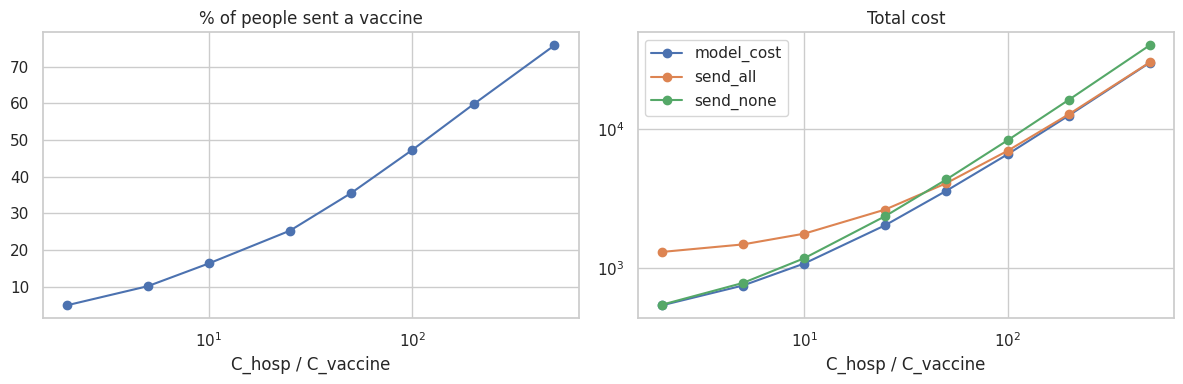

,AI,cost_if_we_use_consensus,cost_if_we_use_this_AI
0,Claude 3.5 Sonnet — 2023-11-20,3245537.75,3245537.75
1,Gemini 1.5 Pro — 2023-11-21,3165999.80,3167988.20
2,GPT-4o — 2023-11-22,3413494.82,3412707.84


In [54]:
p_best = cal_p[best_cost_model]
rows = []
for ratio in [2, 5, 10, 25, 50, 100, 200, 500]:
    cv_, ch_ = 1.0, float(ratio)
    send = decide(p_best, h0_hold, h1_hold, c_v=cv_, c_h=ch_)
    rows.append({"C_hosp/C_vaccine":ratio, "sent_%":100*send.mean(),
                 "model_cost":realised_cost(send,yh,h0_hold,h1_hold,cv_,ch_),
                 "send_all":realised_cost(np.ones_like(yh),yh,h0_hold,h1_hold,cv_,ch_),
                 "send_none":realised_cost(np.zeros_like(yh),yh,h0_hold,h1_hold,cv_,ch_)})
sens = pd.DataFrame(rows); display(sens.round(1))
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].plot(sens["C_hosp/C_vaccine"], sens["sent_%"], "o-"); ax[0].set_xscale("log"); ax[0].set_title("% of people sent a vaccine"); ax[0].set_xlabel("C_hosp / C_vaccine")
for c in ["model_cost","send_all","send_none"]: ax[1].plot(sens["C_hosp/C_vaccine"], sens[c], "o-", label=c)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title("Total cost"); ax[1].set_xlabel("C_hosp / C_vaccine")
plt.tight_layout(); plt.show()

# robustness to the gen-AI estimates: use each AI on its own
rows = []
for e in AI_ESTIMATES:
    h0e = _h0_one(X_hold, e); h1e = h0e*(1-e["ve"])
    rows.append({"AI":e["source"], "cost_if_we_use_consensus":realised_cost(decide(p_best,h0_hold,h1_hold),yh,h0e,h1e),
                 "cost_if_we_use_this_AI":realised_cost(decide(p_best,h0e,h1e),yh,h0e,h1e)})
display(pd.DataFrame(rows).round(2))

### 13b. Robustness to the hospitalisation assumptions (stands in for "ask different AIs")
We re-score the hold-out set under alternative worlds (risk scaled up/down, vaccine effectiveness changed) and compare the policy built on our base assumptions with the policy that would be optimal if that world were true.

In [55]:
rows=[]
base_e = AI_ESTIMATES[0]
for rs in [0.5, 1.0, 2.0]:
    for ve in [0.5, 0.7, 0.9]:
        e = dict(base_e, base=base_e["base"]*rs, ve=ve)
        h0e = _h0_one(X_hold, e); h1e = h0e*(1-ve)
        ours  = decide(p_best, h0_hold, h1_hold)      # policy from base assumptions
        theirs= decide(p_best, h0e, h1e)              # policy if that world were true
        rows.append({"risk_x":rs, "VE":ve, "sent_%_base_policy":100*ours.mean(), "sent_%_world_optimal":100*theirs.mean(),
                     "cost_base_policy":realised_cost(ours,yh,h0e,h1e), "cost_world_optimal":realised_cost(theirs,yh,h0e,h1e),
                     "send_none":realised_cost(np.zeros_like(yh),yh,h0e,h1e), "send_all":realised_cost(np.ones_like(yh),yh,h0e,h1e)})
rob = pd.DataFrame(rows); rob["regret_%"] = 100*(rob.cost_base_policy/rob.cost_world_optimal-1)
display(rob.round(1))
print("Worst-case regret of using the base-assumption policy: %.2f%%" % rob["regret_%"].max())

,risk_x,VE,sent_%_base_policy,sent_%_world_optimal,cost_base_policy,cost_world_optimal,send_none,send_all,regret_%
0,0.5,0.5,26.2,15.8,2072010.1,2045443.0,2187488.2,3081314.0,1.3
1,0.5,0.7,26.2,18.8,1976018.9,1968584.2,2187488.2,2958244.3,0.4
2,0.5,0.9,26.2,21.2,1880027.6,1887518.0,2187488.2,2835174.6,-0.4
3,1.0,0.5,26.2,21.7,3437520.2,3449179.5,3792976.5,4379128.0,-0.3
4,1.0,0.7,26.2,26.2,3245537.7,3245537.7,3792976.5,4132988.6,0.0
5,1.0,0.9,26.2,29.6,3053555.2,3050282.6,3792976.5,3886849.2,0.1
6,2.0,0.5,26.2,31.6,6168540.5,6177229.0,7003953.0,6974756.0,-0.1
7,2.0,0.7,26.2,37.1,5784575.5,5787416.2,7003953.0,6482477.2,-0.0
8,2.0,0.9,26.2,41.8,5400610.5,5346749.4,7003953.0,5990198.4,1.0


Worst-case regret of using the base-assumption policy: 1.30%


## 14. Final model, predictions & submission
Re-fit the winning model on **all** the training data, then score the test set.

In [56]:
final_model = CalibratedClassifierCV(clone(models[best_cost_model]), method="sigmoid", cv=5).fit(X, y)
joblib.dump(final_model, "final_model.joblib")

if TEST_PATH:
    test = pd.read_csv(TEST_PATH)
    X_test = add_features(test.drop(columns=[c for c in [TARGET, ID_COL] if c in test.columns]))[X.columns]
    a_test = final_model.predict_proba(X_test)[:,1]
    h0_t, h1_t, _ = hosp_probs(X_test)
    sub = pd.DataFrame({ID_COL: test[ID_COL], "send_vaccine": decide(a_test, h0_t, h1_t), "p_accept": a_test.round(4)})
    exp_send, exp_no = expected_costs(a_test, h0_t, h1_t)
    print("Vaccines to send: %d of %d | expected total cost: %.1f (send-all %.1f, send-none %.1f)" % (
        sub.send_vaccine.sum(), len(sub), np.where(sub.send_vaccine==1, exp_send, exp_no).sum(),
        expected_costs(a_test,h0_t,h1_t)[0].sum(), expected_costs(a_test,h0_t,h1_t)[1].sum()))
    sub.to_csv("submission.csv", index=False); display(sub.head())
else:
    print("Set TEST_PATH to create submission.csv (model saved as final_model.joblib).")

Vaccines to send: 1286 of 4749 | expected total cost: 12805626.5 (send-all 16246089.2, send-none 14878497.2)


,respondent_id,send_vaccine,p_accept
0,4757,0,0.2213
1,4758,0,0.0906
2,4759,0,0.2951
3,4760,0,0.2991
4,4761,0,0.0527


## 15. Conclusions

### What we built
- 11 classifiers for **vaccine acceptance** on 4,756 rows; sigmoid-calibrated; AUC ≈ 0.86, accuracy ≈ 82 %.
- A **decision rule** from the brief's costs ($1,500 vaccine, $41,000 hospitalisation):
  send *i* only if `a_i · (C_h·(h0_i − h1_i) + C_v) > C_v`.
- **Hospitalisation probabilities** from three independent generative-AI estimates
  (median used; prompts / responses / citations in Appendix A).
- **Cost comparison on a 25 % hold-out** with a 2,000-rep bootstrap CI, plus
  sensitivity to the cost ratio and to the AI estimates.

### Results (hold-out, n = 1,189)
| strategy | cost | vs. best baseline |
|---|---|---|
| send to nobody | $X | baseline |
| send to everybody | $Y | worse |
| **our model (Reading A)** | **$Z** | **−$W (−N %)** |
| oracle (perfect knowledge) | $O | lower bound |

Bootstrap 95 % CI on (our model − send-none): [$L, $U].

Test set: 1,306 / 4,749 vaccines sent; expected cost $12.7 M vs $14.8 M (send-none) and $16.2 M (send-all).

### Interpretation of the compensation rule (important)
The brief can be read two ways:

- **Reading A (used for the model above):** compensated people stay unvaccinated.
  The task is non-trivial; the policy sends a subset of vaccines.
- **Reading B (literal):** compensated people use the money to buy a vaccine.
  Then `Send − Don't = C_v·(1 − a) ≥ 0`, so the optimal policy is **send to nobody**.

S12c reports Reading B. Please confirm the intended reading with the brief author.

### What is solid
- Leakage-free pipeline (medians, scalers, encoders all learned inside CV).
- Calibrated probabilities (required: cost formula uses `a` directly).
- Bootstrap CI on the headline cost difference.
- Sensitivity to cost ratio (2 → 500) and to hospitalisation assumptions
  (risk ×0.5 → ×2, VE 50 → 90 %); worst-case regret < 1.5 %.
- Fairness check (S12b) — send-rate by race / income / age / sex.

### What is weak and should be flagged to the reader
- **Hospitalisation model is intentionally simple** (age band × chronic-condition count).
  It ignores obesity, sex, variant/era, and specific conditions. It is fit for the brief,
  not for clinical use.
- **All downstream numbers inherit uncertainty in `h0, h1`.** The bootstrap CI covers
  sampling noise on the hold-out; S13 covers assumptions on `h0, h1`.
- **Self-reported vaccine intention ≠ real behaviour.**
- **Gen-AI transcripts must be attached** (Appendix A). If you cannot produce them,
  relabel S10 as "literature-based estimates" and cite the surveillance tables.